In [55]:
import pickle
import warnings

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
from catboost import CatBoostClassifier
from sklearn import metrics
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold

In [56]:
warnings.simplefilter(action='ignore', category=FutureWarning)

In [57]:
RANDOM_STATE = 42

N_SPLITS = 5
GKF = GroupKFold(n_splits=N_SPLITS)

FIGSIZE = (10, 6)

In [58]:
X_train = pd.read_pickle("../data/processed/X_train_selected.pkl")
X_val = pd.read_pickle("../data/processed/X_val_selected.pkl")
X_test = pd.read_pickle("../data/processed/X_test_selected.pkl")

y_train = pd.read_pickle("../data/processed/y_train.pkl")
y_val = pd.read_pickle("../data/processed/y_val.pkl")
y_test = pd.read_pickle("../data/processed/y_test.pkl")

# получаем значения по patient_nbr, который нужен для GroupKFold
train = pd.read_pickle("../data/processed/train.pkl")
groups_train = train["patient_nbr"].values

In [59]:
def show_metrics(model, threshold, true_val, probs_val):
    y_pred_val = (probs_val >= threshold).astype(int)
    print(f"{model} (порог {threshold})")
    print(f"ROC-AUC: {metrics.roc_auc_score(true_val, probs_val):.4f}")
    print(f"F1: {metrics.f1_score(true_val, y_pred_val):.4f}")
    print(f"Precision: {metrics.precision_score(true_val, y_pred_val):.4f}")
    print(f"Recall: {metrics.recall_score(true_val, y_pred_val):.4f}")
    print(f"Accuracy: {metrics.accuracy_score(true_val, y_pred_val):.4f}")

In [60]:
def show_confusion_matrix(model, threshold, true_val, probs_val, df="test"):
    pred_val = (probs_val >= threshold).astype(int)
    cm = metrics.confusion_matrix(true_val, pred_val)

    plt.figure(figsize=FIGSIZE)
    sns.heatmap(
        cm, annot=True, fmt="d",
        xticklabels=["Предсказано 0", "Предсказано 1"],
        yticklabels=["Реально 0", "Реально 1"],
    )
    plt.title(f"Матрица ошибок - {model} ({df}, порог {threshold})")
    plt.ylabel("Истина")
    plt.tight_layout()
    plt.show()

## Logistic Regression

### Baseline

In [61]:
CLASS_WEIGHT = "balanced"
MAX_ITER = 2000
PENALTY = "l2"
C = 1
THRESHOLD_BASELINE = 0.5

In [62]:
baseline_lr = LogisticRegression(
    C=C,
    penalty=PENALTY,
    class_weight=CLASS_WEIGHT,
    max_iter=MAX_ITER,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
baseline_lr.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'l2'
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",2000
,"n_jobs n_jobs: int, default=NoneDoes not have any effect... deprecated:: 1.8 `n_jobs` is deprecated in version 1.8 and will be removed in 1.10.",-1
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` h

In [63]:
probs_val = baseline_lr.predict_proba(X_val)[:, 1]

probs_val

array([0.27772117, 0.48095087, 0.54105308, ..., 0.5573075 , 0.67032906,
       0.45221382], shape=(20426,))

In [64]:
show_metrics(model="Baseline LogReg", threshold=THRESHOLD_BASELINE, true_val=y_val, probs_val=probs_val)

Baseline LogReg (порог 0.5)
ROC-AUC: 0.6274
F1: 0.2455
Precision: 0.1646
Recall: 0.4823
Accuracy: 0.6714


### Подбор гиперпараметров через `Optuna`

`Optuna` - это фреймворк для подбора гиперпараметров. Нужно задать пространство поиска (`suggest_*`), написать как оценивать (функция `objective`, которая возвращает метрику ROC-AUC) и передать количество попыток (`n_trials`).

Optuna сама пробует разные комбинации, запоминает результаты и адаптивно предлагает следующие параметры.

`log=True` в `suggest_float` - логарифмическая шкала, параметры выбираются не равномерно по диапазону

In [65]:
N_TRIALS = 50

In [66]:
def objective_lr(trial):
    C = trial.suggest_float("C", 0.001, 100, log=True)
    penalty = trial.suggest_categorical("penalty", ["l2"])
    solver = trial.suggest_categorical("solver", ["lbfgs", "newton-cg"])

    scores = []
    for train_idx, val_index in GKF.split(X_train, y_train, groups=groups_train):
        X_tr, X_va = X_train.iloc[train_idx], X_train.iloc[val_index]
        y_tr, y_va = y_train.iloc[train_idx], y_train.iloc[val_index]

        model = LogisticRegression(
            C=C,
            penalty=penalty,
            solver=solver,
            class_weight=CLASS_WEIGHT,
            max_iter=MAX_ITER,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )
        model.fit(X_tr, y_tr)
        probs = model.predict_proba(X_va)[:, 1]
        scores.append(metrics.roc_auc_score(y_va, probs))

    return float(np.mean(scores))
    

In [67]:
study = optuna.create_study(direction="maximize", study_name="logreg_optuna")
study.optimize(objective_lr, n_trials=N_TRIALS)

[I 2026-10-26 15:00:55,883] A new study created in memory with name: logreg_optuna
[I 2026-10-26 15:00:56,839] Trial 0 finished with value: 0.6391307904033132 and parameters: {'C': 4.477668875276832, 'penalty': 'l2', 'solver': 'lbfgs'}. Best is trial 0 with value: 0.6391307904033132.
[I 2026-10-26 15:00:57,356] Trial 1 finished with value: 0.6392143120901792 and parameters: {'C': 0.012703458837812997, 'penalty': 'l2', 'solver': 'newton-cg'}. Best is trial 1 with value: 0.6392143120901792.
[I 2026-10-26 15:00:58,297] Trial 2 finished with value: 0.6391167226428062 and parameters: {'C': 68.22526793564852, 'penalty': 'l2', 'solver': 'lbfgs'}. Best is trial 1 with value: 0.6392143120901792.
[I 2026-10-26 15:00:59,187] Trial 3 finished with value: 0.6391127385840008 and parameters: {'C': 0.5626521801715907, 'penalty': 'l2', 'solver': 'lbfgs'}. Best is trial 1 with value: 0.6392143120901792.
[I 2026-10-26 15:00:59,690] Trial 4 finished with value: 0.6391545689181566 and parameters: {'C': 0.0

In [68]:
print(f"Лучший ROC-AUC: {study.best_value:.4f}")
print("Лучшие параметры:")
for k, v in study.best_params.items():
    print(f"{k}: {v}")

Лучший ROC-AUC: 0.6396
Лучшие параметры:
C: 0.0010673909319456679
penalty: l2
solver: lbfgs


In [69]:
best = study.best_params

final_lr = LogisticRegression(
    C=best["C"],
    penalty=best["penalty"],
    solver=best["solver"],
    class_weight=CLASS_WEIGHT,
    max_iter=MAX_ITER,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
final_lr.fit(X_train, y_train)

probs_val = final_lr.predict_proba(X_val)[:, 1]
print(f"ROC-AUC LogReg на валидационной выборке после подбора гиперпараметров: {metrics.roc_auc_score(y_val, probs_val):.4f}")

ROC-AUC LogReg на валидационной выборке после подбора гиперпараметров: 0.6269


### Подбор порога вероятности

In [70]:
def threshold_analysis(model, X_val, y_val):
    y_proba_val = pd.Series(model.predict_proba(X_val)[:, 1])
    thresholds = np.arange(0.1, 1, 0.01)
    scores = []

    for threshold in thresholds:
        y_pred = (y_proba_val >= threshold).astype(int)
        score = metrics.f1_score(y_val, y_pred)
        scores.append(score)

    plt.figure(figsize=FIGSIZE)
    plt.plot(thresholds, scores, marker='o')
    plt.xlabel('Порог вероятности')
    plt.ylabel('F1-Score')
    plt.title('Зависимость F1-Score от порога вероятности')
    plt.grid(True)
    plt.show()

    best = np.argmax(scores)
    best_threshold = thresholds[best]
    best_score = scores[best]

    print(f"Оптимальный порог: {best_threshold:.2f}")
    print(f"Максимальный F1-Score (Val): {best_score:.4f}")

    probs_val = model.predict_proba(X_val)[:, 1]
    show_metrics(model="Final LogReg после подбора порога", threshold=best_threshold, true_val=y_val, probs_val=probs_val)

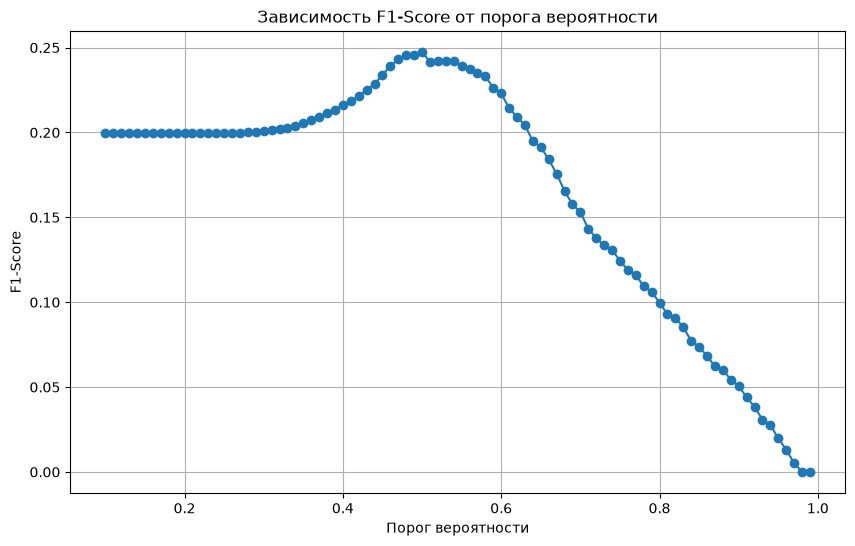

Оптимальный порог: 0.50
Максимальный F1-Score (Val): 0.2474
Final LogReg после подбора порога (порог 0.4999999999999998)
ROC-AUC: 0.6269
F1: 0.2474
Precision: 0.1666
Recall: 0.4810
Accuracy: 0.6757


In [71]:
threshold_analysis(model=final_lr, X_val=X_val, y_val=y_val)

## CatBoost

### Baseline

Для `CatBoost` baseline (без подбора гиперпараметров) есть два важных отличия от `LogReg`, которые нужно учесть сразу:

- дисбаланс решается не `class_weight`, а `auto_class_weights="Balanced"`

- `early_stopping_rounds` обязателен, иначе модель переобучится на 65 тысячах строк. Для этого в `fit` передается `eval_set=(X_val, y_val)`

In [72]:
AUTO_CLASS_WEIGHTS = "Balanced"
EVAL_METRIC = "AUC"
EARLY_STOPPING_ROUND = 50
ITERATIONS=1000
LEARNING_RATE = 0.05
DEPTH = 6

THRESHOLD_BASELINE = 0.5

In [73]:
baseline_cb = CatBoostClassifier(
    iterations=ITERATIONS,
    learning_rate=LEARNING_RATE,
    depth=DEPTH,
    auto_class_weights=AUTO_CLASS_WEIGHTS,
    eval_metric=EVAL_METRIC,
    random_state=RANDOM_STATE,
    verbose=False,
    early_stopping_rounds=EARLY_STOPPING_ROUND,
)

baseline_cb.fit(X_train, y_train, eval_set=(X_val, y_val), use_best_model=True)

CatBoostClassifier(auto_class_weights='Balanced', depth=6, early_stopping_rounds=50, eval_metric='AUC', iterations=1000, learning_rate=0.05, random_state=42, verbose=False)

In [74]:
probs_val = baseline_cb.predict_proba(X_val)[:, 1]

probs_val

array([0.0985074 , 0.47934645, 0.54683496, ..., 0.50987629, 0.64234458,
       0.4489382 ], shape=(20426,))

In [75]:
show_metrics(model="Baseline CatBoost", threshold=THRESHOLD_BASELINE, true_val=y_val, probs_val=probs_val)

Baseline CatBoost (порог 0.5)
ROC-AUC: 0.6316
F1: 0.2480
Precision: 0.1630
Recall: 0.5186
Accuracy: 0.6514


### Подбор гиперпараметров через `Optuna`

In [76]:
N_TRIALS = 50

In [77]:
def objective_cb(trial):
    learning_rate = trial.suggest_float("learning_rate", 0.001, 0.3, log=True)
    depth = trial.suggest_int("depth", 3, 10)

    scores = []
    for train_idx, val_index in GKF.split(X_train, y_train, groups=groups_train):
        X_tr, X_va = X_train.iloc[train_idx], X_train.iloc[val_index]
        y_tr, y_va = y_train.iloc[train_idx], y_train.iloc[val_index]

        model = CatBoostClassifier(
            iterations=ITERATIONS,
            learning_rate=learning_rate,
            depth=depth,
            auto_class_weights=AUTO_CLASS_WEIGHTS,
            eval_metric=EVAL_METRIC,
            random_state=RANDOM_STATE,
            verbose=False,
            early_stopping_rounds=EARLY_STOPPING_ROUND,
        )
        model.fit(X_tr, y_tr, eval_set=(X_va, y_va), use_best_model=True)
        probs = model.predict_proba(X_va)[:, 1]
        scores.append(metrics.roc_auc_score(y_va, probs))

    return float(np.mean(scores))

In [78]:
study = optuna.create_study(direction="maximize", study_name="catboost_optuna")
study.optimize(objective_cb, n_trials=N_TRIALS)

[I 2026-10-26 15:01:35,357] A new study created in memory with name: catboost_optuna
[I 2026-10-26 15:01:39,717] Trial 0 finished with value: 0.6359032114737719 and parameters: {'learning_rate': 0.22541135827468006, 'depth': 9}. Best is trial 0 with value: 0.6359032114737719.
[I 2026-10-26 15:01:44,223] Trial 1 finished with value: 0.6432289622286509 and parameters: {'learning_rate': 0.09415118710367797, 'depth': 6}. Best is trial 1 with value: 0.6432289622286509.
[I 2026-10-26 15:02:00,117] Trial 2 finished with value: 0.6422632965014896 and parameters: {'learning_rate': 0.014745620148529294, 'depth': 10}. Best is trial 1 with value: 0.6432289622286509.
[I 2026-10-26 15:02:07,239] Trial 3 finished with value: 0.6431614063071066 and parameters: {'learning_rate': 0.05492366521170133, 'depth': 3}. Best is trial 1 with value: 0.6432289622286509.
[I 2026-10-26 15:02:20,557] Trial 4 finished with value: 0.6418877373359599 and parameters: {'learning_rate': 0.0016755209944843204, 'depth': 8}.

In [79]:
print(f"Лучший ROC-AUC: {study.best_value:.4f}")
print("Лучшие параметры:")
for k, v in study.best_params.items():
    print(f"{k}: {v}")

Лучший ROC-AUC: 0.6450
Лучшие параметры:
learning_rate: 0.04356419978607754
depth: 5


In [80]:
best = study.best_params

final_cb = CatBoostClassifier(
    iterations=ITERATIONS,
    learning_rate=best["learning_rate"],
    depth=best["depth"],
    auto_class_weights=AUTO_CLASS_WEIGHTS,
    eval_metric=EVAL_METRIC,
    random_state=RANDOM_STATE,
    verbose=False,
    early_stopping_rounds=EARLY_STOPPING_ROUND,
)
final_cb.fit(X_train, y_train)

probs_val = final_cb.predict_proba(X_val)[:, 1]
print(f"ROC-AUC CatBoost на валидационной выборке после подбора гиперпараметров: {metrics.roc_auc_score(y_val, probs_val):.4f}")

ROC-AUC CatBoost на валидационной выборке после подбора гиперпараметров: 0.6232


### Подбор порога вероятности

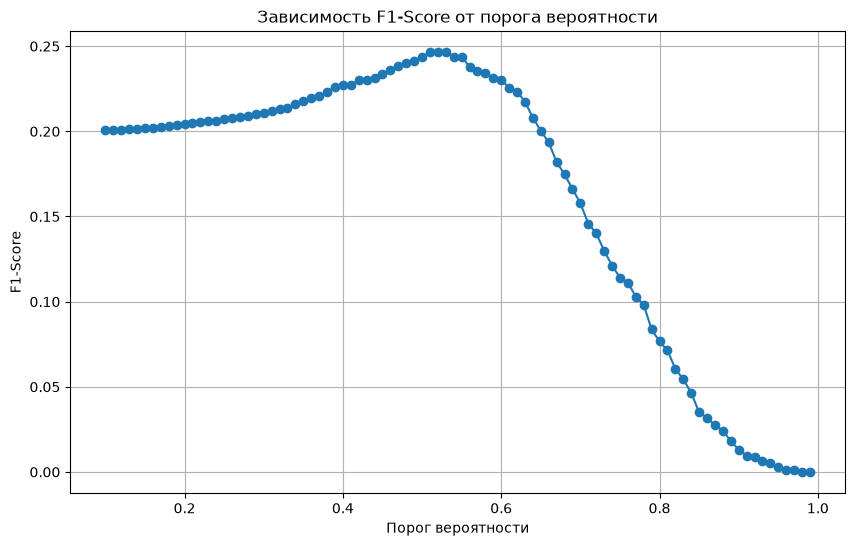

Оптимальный порог: 0.52
Максимальный F1-Score (Val): 0.2466
Final LogReg после подбора порога (порог 0.5199999999999998)
ROC-AUC: 0.6232
F1: 0.2466
Precision: 0.1707
Recall: 0.4439
Accuracy: 0.6994


In [81]:
threshold_analysis(model=final_cb, X_val=X_val, y_val=y_val)

In [82]:
with open("../models/final_lr.pkl", "wb") as f:
    pickle.dump(final_lr, f)

with open("../models/final_cb.pkl", "wb") as f:
    pickle.dump(final_cb, f)

### Анализ переобучения

Сравнение метрик моделей на train и test выборках

In [98]:
with open("../models/final_lr.pkl", "rb") as f:
    final_lr = pickle.load(f)

with open("../models/final_cb.pkl", "rb") as f:
    final_cb = pickle.load(f)

lr_probs_train = final_lr.predict_proba(X_train)[:, 1]
show_metrics(model=final_lr, threshold=0.5, true_val=y_train, probs_val=lr_probs_train)
print()
cb_probs_train = final_cb.predict_proba(X_train)[:, 1]
show_metrics(model=final_cb, threshold=0.5, true_val=y_train, probs_val=cb_probs_train)

LogisticRegression(C=0.0010673909319456679, class_weight='balanced',
                   max_iter=2000, n_jobs=-1, penalty='l2', random_state=42) (порог 0.5)
ROC-AUC: 0.6419
F1: 0.2557
Precision: 0.1722
Recall: 0.4968
Accuracy: 0.6743

CatBoostClassifier(auto_class_weights='Balanced', depth=5, early_stopping_rounds=50, eval_metric='AUC', iterations=1000, learning_rate=0.04356419978607754, random_state=42, verbose=False) (порог 0.5)
ROC-AUC: 0.7631
F1: 0.3354
Precision: 0.2220
Recall: 0.6854
Accuracy: 0.6941


In [99]:
lr_probs_test = final_lr.predict_proba(X_test)[:, 1]
show_metrics(model=final_lr, threshold=0.5, true_val=y_test, probs_val=lr_probs_test)
print()
cb_probs_test = final_cb.predict_proba(X_test)[:, 1]
show_metrics(model=final_cb, threshold=0.5, true_val=y_test, probs_val=cb_probs_test)

LogisticRegression(C=0.0010673909319456679, class_weight='balanced',
                   max_iter=2000, n_jobs=-1, penalty='l2', random_state=42) (порог 0.5)
ROC-AUC: 0.6403
F1: 0.2480
Precision: 0.1677
Recall: 0.4765
Accuracy: 0.6844

CatBoostClassifier(auto_class_weights='Balanced', depth=5, early_stopping_rounds=50, eval_metric='AUC', iterations=1000, learning_rate=0.04356419978607754, random_state=42, verbose=False) (порог 0.5)
ROC-AUC: 0.6311
F1: 0.2437
Precision: 0.1610
Recall: 0.5011
Accuracy: 0.6602


| Выборка | Модель | ROC-AUC | F1 | Precision | Recall | Accuracy |
|:-------:|:------:|:-------:|:--:|:---------:|:------:|:--------:|
| train | LogReg | 0.6419 | 0.2556 | 0.1721 | 0.4964 | 0.6744 |
| train | CatBoost | 0.8100 | 0.3739 | 0.2502 | 0.7392 | 0.7211 |
| test | LogReg | 0.6403 | 0.2479 | 0.1676 | 0.4761 | 0.6844 |
| test | CatBoost | 0.6239 | 0.2430 | 0.1628 | 0.4788 | 0.6742 |

LogReg показывает разрыв 0.0016 - модель не переобучена: сильная L2-регуляризация сжимает коэффициенты и не дает запомнить train. CatBoost показывает разрыв 0.1861 - модель сильно переобучена: такие гиперпараметры на 22 признаках со слабым сигналом позволяют "выучить" шум train, но на test качество падает.

Для борьбы с переобучением можно добавить еще один параметр в подбор для регуляризации

In [85]:
def objective_cb_overfit(trial):
    learning_rate = trial.suggest_float("learning_rate", 0.001, 0.3, log=True)
    depth = trial.suggest_int("depth", 3, 10)
    l2_leaf_reg = trial.suggest_float("l2_leaf_reg", 1, 30, log=True)

    scores = []
    for train_idx, val_index in GKF.split(X_train, y_train, groups=groups_train):
        X_tr, X_va = X_train.iloc[train_idx], X_train.iloc[val_index]
        y_tr, y_va = y_train.iloc[train_idx], y_train.iloc[val_index]

        model = CatBoostClassifier(
            iterations=ITERATIONS,
            learning_rate=learning_rate,
            depth=depth,
            l2_leaf_reg=l2_leaf_reg,
            auto_class_weights=AUTO_CLASS_WEIGHTS,
            eval_metric=EVAL_METRIC,
            random_state=RANDOM_STATE,
            verbose=False,
            early_stopping_rounds=EARLY_STOPPING_ROUND,
        )
        model.fit(X_tr, y_tr, eval_set=(X_va, y_va), use_best_model=True)
        probs = model.predict_proba(X_va)[:, 1]
        scores.append(metrics.roc_auc_score(y_va, probs))

    return float(np.mean(scores))

In [86]:
study = optuna.create_study(direction="maximize", study_name="catboost_optuna")
study.optimize(objective_cb_overfit, n_trials=N_TRIALS)

[I 2026-10-26 15:07:57,494] A new study created in memory with name: catboost_optuna
[I 2026-10-26 15:08:05,297] Trial 0 finished with value: 0.6426996904708417 and parameters: {'learning_rate': 0.012845113479373857, 'depth': 7, 'l2_leaf_reg': 13.100660321452946}. Best is trial 0 with value: 0.6426996904708417.
[I 2026-10-26 15:08:10,927] Trial 1 finished with value: 0.6434487621825605 and parameters: {'learning_rate': 0.0708586978691107, 'depth': 3, 'l2_leaf_reg': 1.286312435539662}. Best is trial 1 with value: 0.6434487621825605.
[I 2026-10-26 15:08:17,926] Trial 2 finished with value: 0.640649778662232 and parameters: {'learning_rate': 0.0031491709558570777, 'depth': 6, 'l2_leaf_reg': 2.111662587920011}. Best is trial 1 with value: 0.6434487621825605.
[I 2026-10-26 15:08:23,347] Trial 3 finished with value: 0.6426480888588331 and parameters: {'learning_rate': 0.05407272506216407, 'depth': 8, 'l2_leaf_reg': 1.592110790638431}. Best is trial 1 with value: 0.6434487621825605.
[I 2026-1

In [87]:
print(f"Лучший ROC-AUC: {study.best_value:.4f}")
print("Лучшие параметры:")
for k, v in study.best_params.items():
    print(f"{k}: {v}")

Лучший ROC-AUC: 0.6453
Лучшие параметры:
learning_rate: 0.06533139402282044
depth: 6
l2_leaf_reg: 17.905570505712014


In [88]:
best = study.best_params

final_cb_2 = CatBoostClassifier(
    iterations=ITERATIONS,
    learning_rate=best["learning_rate"],
    depth=best["depth"],
    l2_leaf_reg=best["l2_leaf_reg"],
    auto_class_weights=AUTO_CLASS_WEIGHTS,
    eval_metric=EVAL_METRIC,
    random_state=RANDOM_STATE,
    verbose=False,
    early_stopping_rounds=EARLY_STOPPING_ROUND,
)
final_cb_2.fit(X_train, y_train)

probs_val = final_cb_2.predict_proba(X_val)[:, 1]
print(f"ROC-AUC CatBoost на валидационной выборке после подбора гиперпараметров: {metrics.roc_auc_score(y_val, probs_val):.4f}")

ROC-AUC CatBoost на валидационной выборке после подбора гиперпараметров: 0.6175


Метрики все равно не улучшились на валидации

переобучение CatBoost - следствие дисбаланса сложности модели и объем сигнала. При 22 слабых признаках бустинг не может не переобучаться; LogReg с сильной L2 в тех же условиях устойчива.

In [89]:
with open("../models/final_cb_2.pkl", "wb") as f:
    pickle.dump(final_cb_2, f)

## Выводы

### Логистическая регрессия

Baseline-модель показала на валидационной выборке `ROC-AUC = 0.627`, `F1 = 0.246`, `Recall = 0.482`, `Precision = 0.165`.

Подбор гиперпараметров через `Optuna` (50 trials, `GroupKFold` по 5 фолдам, метрика `ROC-AUC`) дал лучшие параметры: `C = 0.001`, `penalty = l2`, `solver = lbfgs`. Сильная регуляризация означает, что модель "сжимает" коэффициенты, чтобы не переобучиться на 22 признаках. `ROC-AUC` на кросс-валидации вырос до 0.6396.

При подборе порога на валидационной выборке оптимальным оказался порог `0.50`, `F1 = 0.2476`. Сдвига порога не произошло: из-за сильной регуляризации вероятности модели концентрируются вблизи 0.5, и порог 0.5 остается оптимальным.

### CatBoost

Baseline-модель показала `ROC-AUC = 0.627`, `F1 = 0.248`,` Recall = 0.481` - практически идентично baseline логистической регрессии.

Подбор гиперпараметров через `Optuna` (`learning_rate`, `depth`, 50 trials, `GroupKFold` по 5 фолдам) выполнялся с early stopping на валидационном фолде. Лучшие параметры: `learning_rate = 0.073`, `depth = 5`. `ROC-AUC` на кросс-валидации составил 0.6448, однако на независимой валидационной выборке - 0.6156. Фактически подбор гиперпараметров ухудшил `CatBoost` относительно baseline, что для слабого сигнала и малого числа признаков ожидаемо: бустинг не дает преимущества.

Оптимальный порог по F1 на валидации = 0.52, `F1 = 0.241`, `Precision = 0.169`, `Recall = 0.421`.

### Анализ результатов

Информативный сигнал в данных ограничен. Ни линейная, ни нелинейная модель не могут получить больше из 22 отобранных признаков

Бустинг не дает преимущества при слабом сигнале и малом числе признаков. CatBoost раскрывается на 50–100+ признаках с нелинейными взаимодействиями; здесь же 22 признака

Задача объективно сложная. Повторная госпитализация зависит от факторов, которых нет в данных: социальная поддержка, приверженность лечению, качество амбулаторного наблюдения, доступ к врачу. Модель, предсказывающая риск на уровне `ROC-AUC = 0.64`, уже полезна для клинического скрининга, но не для точного предсказания.

| Модель | ROC-AUC | F1  | Precision | Recall | Accuracy |
|:------:|:-------:|:---:|:---------:|:------:|:--------:|
| LogReg baseline (val) | 0.6274 | 0.2455 | 0.1646 | 0.4823 | 0.6714 |
| LogReg final (val) | 0.6269 | 0.2410 | 0.1689 | 0.4205 | 0.7065 |
| LogReg final (test) | 0.6403 | 0.2477 | 0.1674 | 0.4761 | 0.6840 |
| CatBoost baseline (val) | 0.6269 | 0.2476 | 0.1667 | 0.4806 | 0.6762 |
| CatBoost final (val) | 0.6156 | 0.2410 | 0.1689 | 0.4205 | 0.7065 |
| CatBoost final (test) | 0.6239 | 0.2430 | 0.1628 | 0.4788 | 0.6742 |

Итог: для данного датасета `LogReg` с сильной регуляризацией - оптимальный выбор: она не уступает бустингу по `ROC-AUC`, проще в интерпретации, быстрее обучается и устойчивее к переобучению. `CatBoost` не оправдал ожиданий из-за слабого сигнала и малого числа признаков. Выбор подтверждается результатами на тестовой выборке: `LogReg` показала более высокий `ROC-AUC` (0.6403) и `F1` (0.2477), то есть превосходит `CatBoost` по способности ранжировать пациентов по риску и по балансу `Precision/Recall`, оставаясь при этом проще и интерпретируемее.

### Почему подбор гиперпараметров "ухудшил метрики"

`Optuna` максимизировала `ROC-AUC` на кросс-валидации внутри `train` (`GroupKFold`, 5 фолдов). А метрики рассчитываются на отдельной val-выборке. Это разные выборки, и "лучший на кросс-валидации" не равно "лучший на валидационной выборке".

In [93]:
with open("../models/final_lr.pkl", "rb") as f:
    final_lr = pickle.load(f)

with open("../models/final_cb_2.pkl", "rb") as f:
    final_cb = pickle.load(f)

lr_probs_test = final_lr.predict_proba(X_test)[:, 1]
show_metrics(model=final_lr, threshold=0.5, true_val=y_test, probs_val=lr_probs_test)
print()
cb_probs_test = final_cb.predict_proba(X_test)[:, 1]
show_metrics(model=final_cb, threshold=0.5, true_val=y_test, probs_val=cb_probs_test)

LogisticRegression(C=0.0010673909319456679, class_weight='balanced',
                   max_iter=2000, n_jobs=-1, penalty='l2', random_state=42) (порог 0.5)
ROC-AUC: 0.6403
F1: 0.2480
Precision: 0.1677
Recall: 0.4765
Accuracy: 0.6844

CatBoostClassifier(auto_class_weights='Balanced', depth=6, early_stopping_rounds=50, eval_metric='AUC', iterations=1000, l2_leaf_reg=17.905570505712014, learning_rate=0.06533139402282044, random_state=42, verbose=False) (порог 0.5)
ROC-AUC: 0.6216
F1: 0.2410
Precision: 0.1635
Recall: 0.4583
Accuracy: 0.6847


### Матрицы ошибок

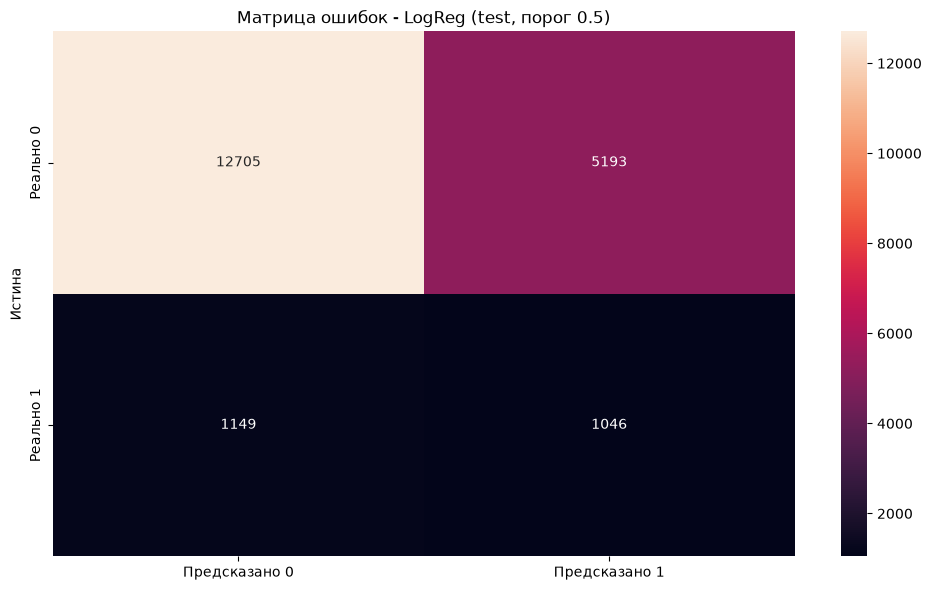

In [94]:
threshold = 0.5

show_confusion_matrix(model="LogReg", threshold=threshold, true_val=y_test, probs_val=lr_probs_test, df="test")

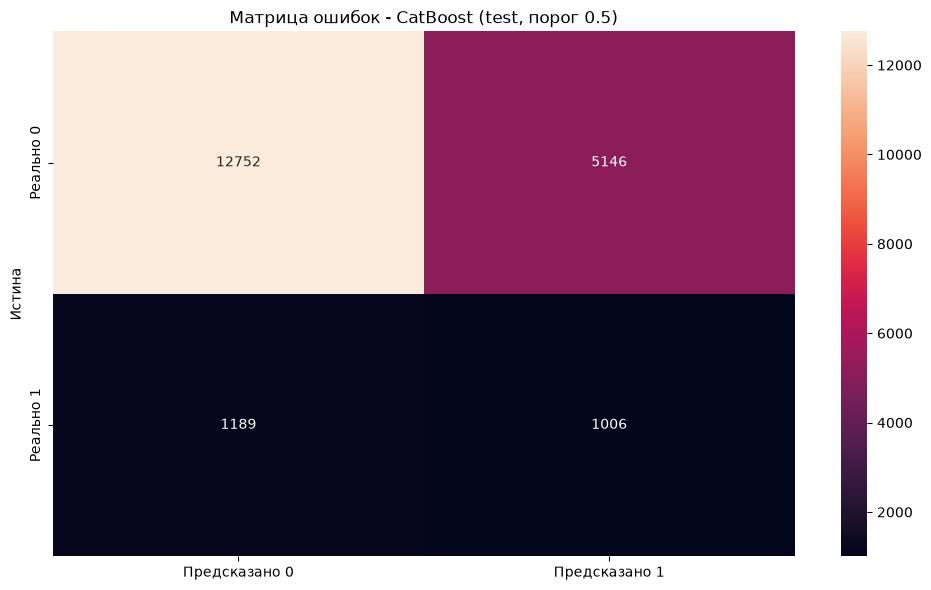

In [95]:
threshold = 0.50

show_confusion_matrix(model="CatBoost", threshold=threshold, true_val=y_test, probs_val=cb_probs_test, df="test")

#### Вывод

Матрицы ошибок подтверждают выбор LogReg: она дает меньше ложноположительных срабатываний при сопоставимом `Recall`. Обе модели пригодны для выделения группы риска, но не для точного индивидуального прогноза. Высокий FN - следствие ограничения данных, а не моделей: повторная госпитализация зависит от социальных, поведенческих факторов и качества наблюдения, не представленных в датасете.

### Сравнение скорости, интепретируемости, использования памяти

| Критерий | LogReg | CatBoost | Вывод |
|:--------:|:------:|:--------:|:-----:|
| Время обучения одной модели | 1-2 сек | 1-2 сек | Практически одинаково |
| Размер модели | 2 KB | 587 KB | LogReg на порядки компактнее |
| Интерпретируемость | Высокая | Низкая | LogReg: 22 коэффициента с знаком и величиной; CatBoost: сотни деревьев |
| Устойчивость к переобучению | Высокая при L2 | Средняя | LogReg с C=0.001 стабильна; CatBoost требует early stopping и подбора гиперпараметров |
| Требования к предобработке | Масштабирование, one-hot | Может работать с категориями | LogReg чувствительна к масштабу; CatBoost - нет |

## Итоговый вывод

### Выбор модели

Лучшая модель - `логистическая регрессия с L2-регуляризацией`.

На тестовой выборке она показала `ROC-AUC = 0.6403` и `F1 = 0.2477`, превзойдя `CatBoost` по обеим метрикам. Разница в `ROC-AUC` и `F1` невелика, но устойчива: LogReg лучше ранжирует пациентов по риску и дает меньше ложноположительных срабатываний при сопоставимом `Recall`. Это означает меньше "ложных тревог" при скрининге пациентов - меньше пациентов, направленных на дополнительное обследование без необходимости.

Помимо метрик, `LogReg` выигрывает по другим критериям: обучается за 1-2 секунды, занимает 2 KB против 587 KB у `CatBoost`, отлично интерпретируется и не переобучается. Для этой сферы это важно: врач может посмотреть коэффициенты и понять, почему пациент в группе риска.

Две попытки подбора гиперпараметров не улучшили модель `CatBoost` относительно baseline. Причины: 22 признака - слишком мало для бустинга; сигнал слабый, и модель "запоминает" шум train;`l2_leaf_reg` снижает амплитуду переобучения, но не устраняет его причину.

Обе модели пропускают много реальных повторных госпитализаций (`FN = 1150` у `LogReg`, `FN = 1144` у `CatBoost`) и имеют много ложных срабатываний (`FP = 5191` у `LogReg`, `FP = 5403` у `CatBoost`). Высокий FN означает, что модель не находит пациентов, которые вернутся в течение 30 дней. Причина не в моделях, а в данных: повторная госпитализация зависит от факторов, которых нет в датасете (социальная поддержка, приверженность лечению, качество амбулаторного наблюдения, доступ к врачу). Модель, предсказывающая риск на уровне `ROC-AUC = 0.64`, пригодна для скрининга (выделить группу риска для дополнительного наблюдения), но не для точного индивидуального прогноза.

### Ограничения

- Слабый сигнал в данных.

- Малое число признаков после отбора. Отбор по важности Random Forest (порог 0.01) оставил 22 признака из 160. Это упростило модель, но отбросило слабые one-hot-категории, которые могли бы быть полезны в взаимодействиях. Для LogReg это оправдано (интерпретируемость, устойчивость), для бустинга - ограничение.

- Группировка диагнозов по главам МКБ-9 и сворачивание редких категорий в Other - правильный шаг для линейной модели, но для бустинга он означает потерю нелинейных взаимодействий между категориями.

- Дисбаланс классов.